## Сравнение моделей

In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))
from sklearn.pipeline import Pipeline
from src.transformers import DataCleaner, LifesquareKNNImputer, HealthcareKNNImputer, FeaturesCreator, SimpleDataCleaner
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import pandas as pd
from src.utils import evaluate_preds, save_res, reduce_mem_usage
import json
from pathlib import Path
import optuna
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import joblib


In [2]:
df = pd.read_csv('../data/raw/train.csv')
X = df.drop('Price', axis=1)
y = df['Price']
preprocessor = Pipeline(steps=[
    ('cleaner', DataCleaner()),
    ('imputer_lifesquare', LifesquareKNNImputer()),
    ('imputer_healthcare', HealthcareKNNImputer()),
    ('feature_creator', FeaturesCreator())
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train = preprocessor.fit_transform(X_train, y_train)
X_test = preprocessor.transform(X_test)


In [3]:
res_table = pd.DataFrame(index=['baseline', 'Линейная регрессия', 'Решающее дерево', 'Случайный лес', 'Градиентный бустинг', 'CatBoost', 'XGBoost', 'lightGBM'], columns=['rmse', 'r2'])

## Построим baseline

d:\regression_house_price\src\transformers.py:300: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X['LifeSquare'].fillna(self.median_lifesquare_, inplace=True)
d:\regression_house_price\src\transformers.py:301: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'd

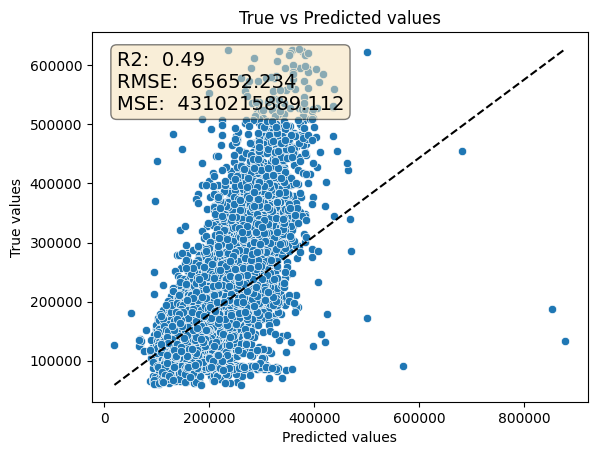

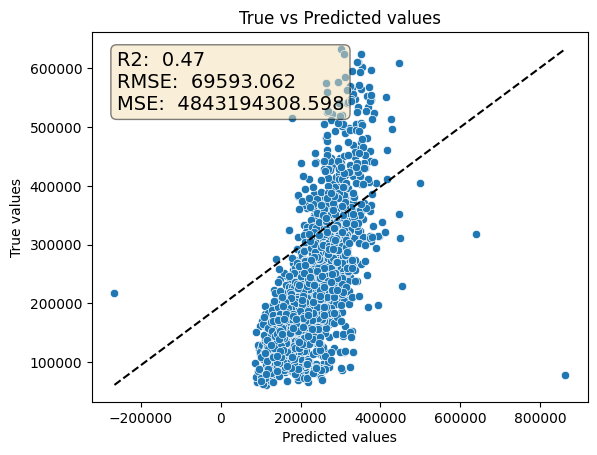

In [4]:
base_preprocessor = Pipeline(steps=[
    ('base_cleaner', SimpleDataCleaner())
])
X_bl_train, X_bl_test, y_bl_train, y_bl_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_bl_train = base_preprocessor.fit_transform(X_bl_train)
X_bl_test = base_preprocessor.transform(X_bl_test)
bl_scaler = StandardScaler()
X_bl_train = bl_scaler.fit_transform(X_bl_train, y_bl_train)
X_bl_test = bl_scaler.transform(X_bl_test)
lr_base = LinearRegression()
lr_base.fit(X_bl_train, y_bl_train)
y_bl_pred_train = lr_base.predict(X_bl_train)
y_bl_pred_test = lr_base.predict(X_bl_test)
evaluate_preds(y_bl_train, y_bl_pred_train)
r2_val, rmse_val = evaluate_preds(y_bl_test, y_bl_pred_test)
save_res('baseline', r2_val, rmse_val, res_table)

## Линейная регрессия 

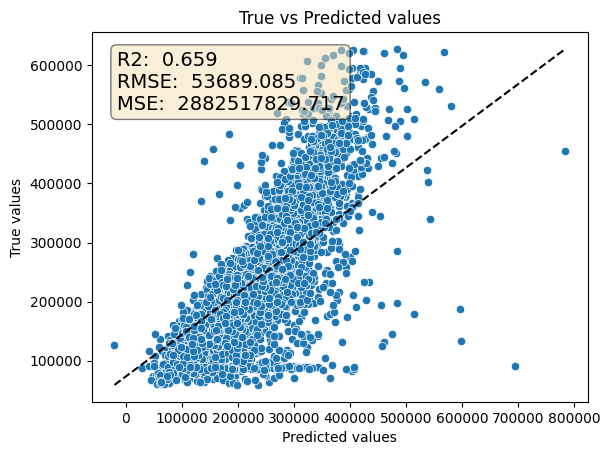

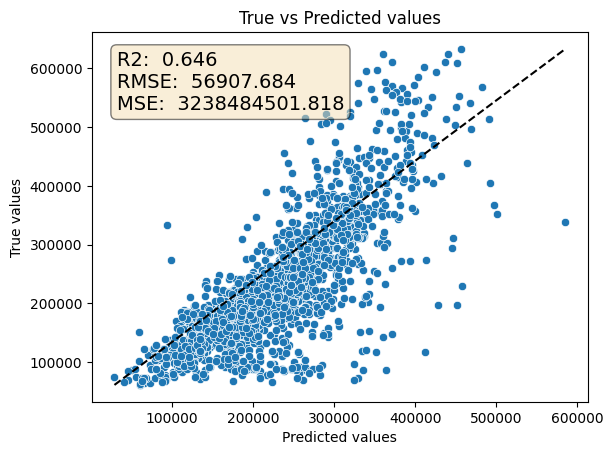

In [5]:
lr_scaler = StandardScaler()
X_lr_train = lr_scaler.fit_transform(X_train)
X_lr_test = lr_scaler.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_lr_train, y_train)
y_lr_pred_train = lr_model.predict(X_lr_train)
y_lr_pred_test = lr_model.predict(X_lr_test)
evaluate_preds(y_train, y_lr_pred_train)
r2_val, rmse_val = evaluate_preds(y_test, y_lr_pred_test)
save_res('Линейная регрессия', r2_val, rmse_val, res_table)

## Решающее деревео

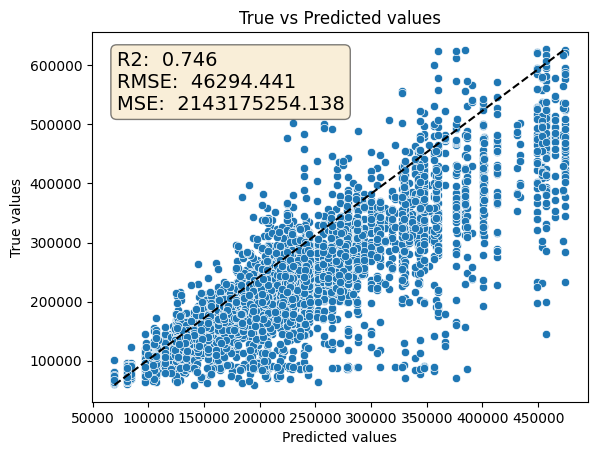

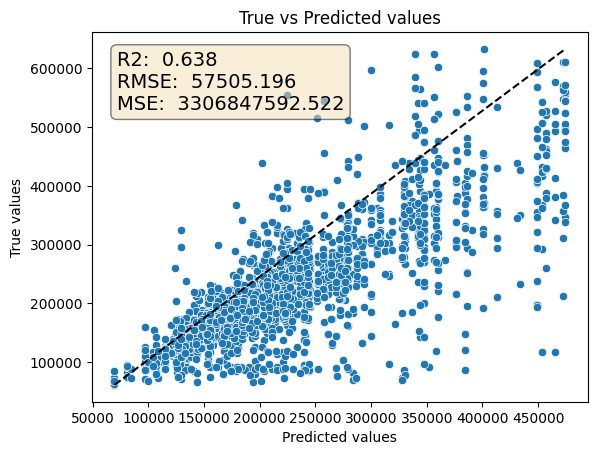

In [6]:
dt_model = DecisionTreeRegressor()

project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "DecisionTree"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    param_grid = {
            "max_depth": optuna.distributions.IntDistribution(1, 100),
            "min_samples_split": optuna.distributions.IntDistribution(2, 100),
            "min_samples_leaf": optuna.distributions.IntDistribution(1, 50),
            "max_features": optuna.distributions.CategoricalDistribution(['auto', 'sqrt', 'log2']),      
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                dt_model,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring='neg_root_mean_squared_error',
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = optuna_search.best_params_

    model_info = {
                "model_name": "DecisionTree",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

dt_model = DecisionTreeRegressor(**best_params_)
dt_model.fit(X_train, y_train)
y_dt_pred_train = dt_model.predict(X_train)
y_dt_pred_test = dt_model.predict(X_test)
evaluate_preds(y_train, y_dt_pred_train)
r2_val, rmse_val = evaluate_preds(y_test, y_dt_pred_test)
save_res('Решающее дерево', r2_val, rmse_val, res_table)

## Случайный лес

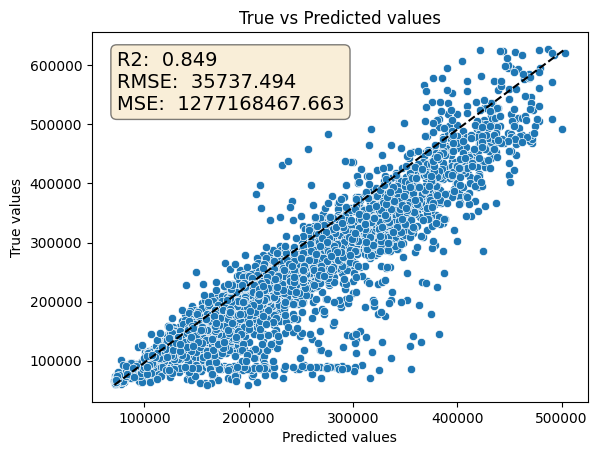

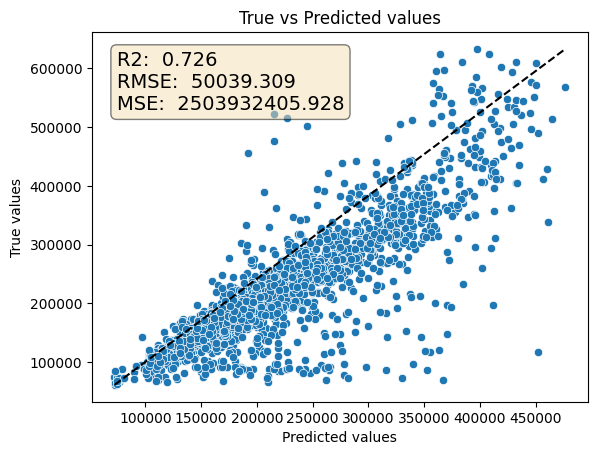

In [7]:
rf_model = RandomForestRegressor()
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "RandomForest"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    param_grid = {
            "max_depth": optuna.distributions.IntDistribution(1, 30),
            "min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "n_estimators": optuna.distributions.IntDistribution(20, 500)      
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                rf_model,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring='neg_root_mean_squared_error',
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = optuna_search.best_params_

    model_info = {
                "model_name": "RandomForest",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

rf_model = RandomForestRegressor(**best_params_)
rf_model.fit(X_train, y_train)
y_rf_pred_train = rf_model.predict(X_train)
y_rf_pred_test = rf_model.predict(X_test)
evaluate_preds(y_train, y_rf_pred_train)
r2_val, rmse_val = evaluate_preds(y_test, y_rf_pred_test)
save_res('Случайный лес', r2_val, rmse_val, res_table)


## Градиентный бустинг

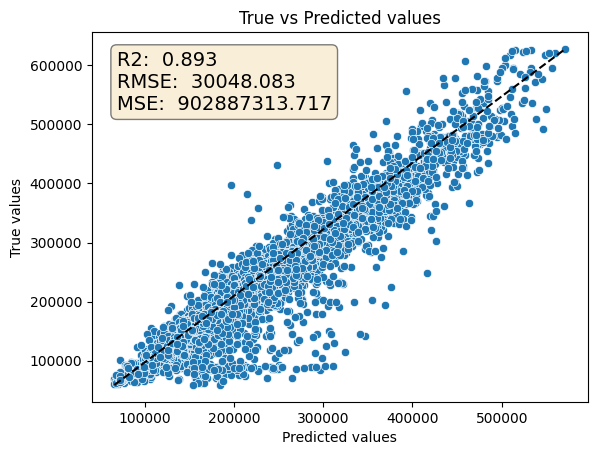

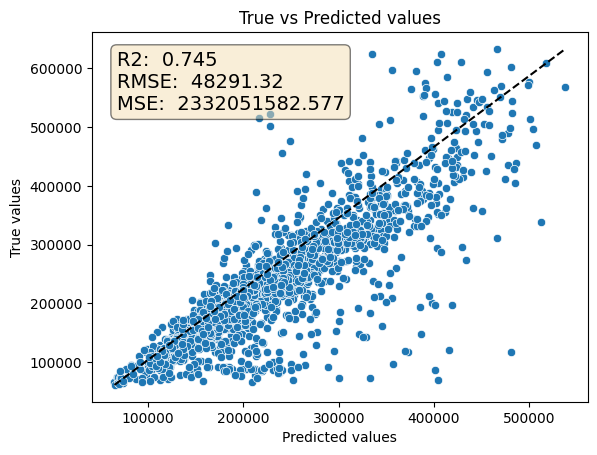

In [8]:
gb_model = GradientBoostingRegressor()
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "GradientBoosting"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    param_grid = {
            "max_depth": optuna.distributions.IntDistribution(1, 10),
            "min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "n_estimators": optuna.distributions.IntDistribution(20, 1500, log=True),
            "learning_rate": optuna.distributions.FloatDistribution(1e-5, 0.5, log=True)      
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                gb_model,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring='neg_root_mean_squared_error',
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = optuna_search.best_params_

    model_info = {
                "model_name": "GradientBoosting",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

gb_model = GradientBoostingRegressor(**best_params_)
gb_model.fit(X_train, y_train)
y_gb_pred_train = gb_model.predict(X_train)
y_gb_pred_test = gb_model.predict(X_test)
evaluate_preds(y_train, y_gb_pred_train)
r2_val, rmse_val = evaluate_preds(y_test, y_gb_pred_test)
save_res('Градиентный бустинг', r2_val, rmse_val, res_table)


## CatBoost

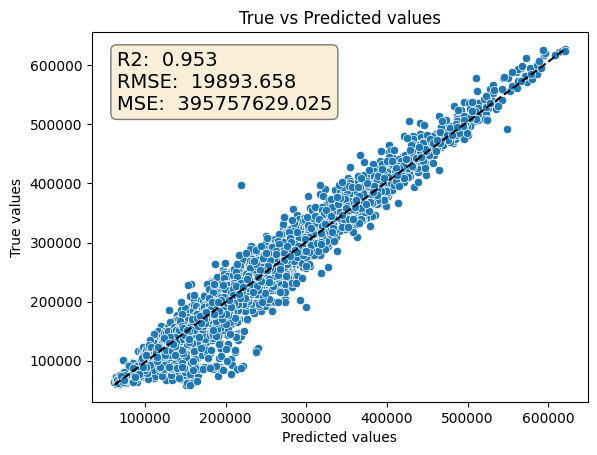

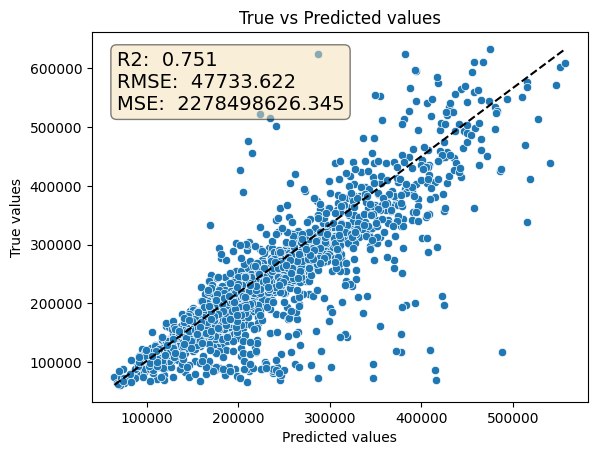

In [9]:
CAT_FEATURE_NAMES = ['DistrictId', 'Rooms', 'Floor', 'HouseYear']
CAT_FEATURE_NAMES = ['DistrictId', 'Floor', 'HouseYear']
frozen_params = {
     'silent':True,
     #'cat_features':CAT_FEATURE_NAMES,
     'eval_metric':'RMSE',
     'early_stopping_rounds':20,
     'random_state':42
}
cb_model = CatBoostRegressor(**frozen_params)
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "CatBoost"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    param_grid = {
            "depth": optuna.distributions.IntDistribution(2, 10),
            "l2_leaf_reg": optuna.distributions.FloatDistribution(1e-2, 15, log=True),
            "iterations": optuna.distributions.IntDistribution(20, 1500, log=True),
            "learning_rate": optuna.distributions.FloatDistribution(1e-5, 0.5, log=True)      
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                cb_model,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring='neg_root_mean_squared_error',
                random_state=42
            )

    optuna_search.fit(X_train, y_train, cat_features=CAT_FEATURE_NAMES)
    best_params_ = optuna_search.best_params_

    model_info = {
                "model_name": "CatBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

cb_model = CatBoostRegressor(**frozen_params, **best_params_)
cb_model.fit(X_train, y_train)
y_cb_pred_train = cb_model.predict(X_train)
y_cb_pred_test = cb_model.predict(X_test)
evaluate_preds(y_train, y_cb_pred_train)
r2_val, rmse_val = evaluate_preds(y_test, y_cb_pred_test)
save_res('CatBoost', r2_val, rmse_val, res_table)


## XGBoost

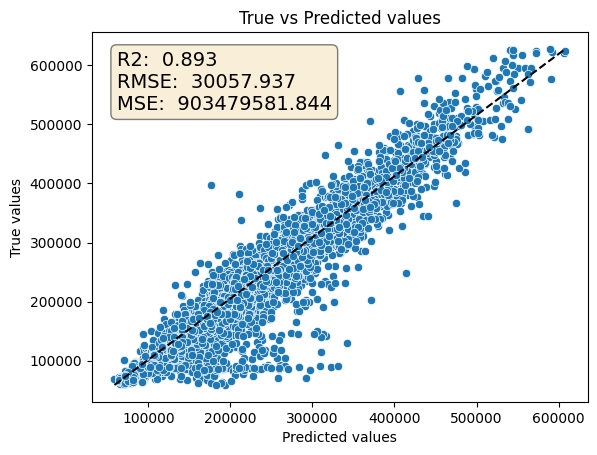

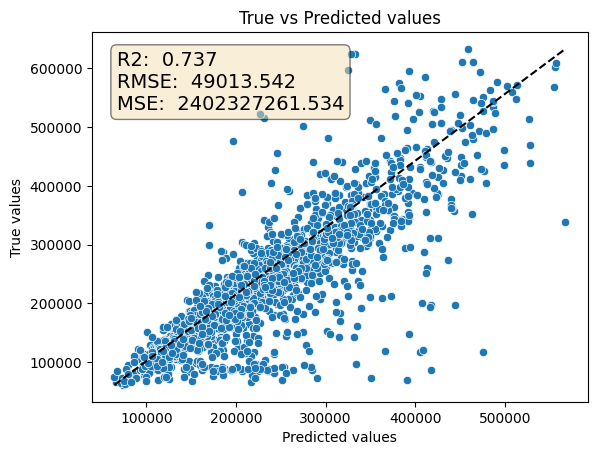

In [10]:
xg_model = XGBRegressor()

if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "XGBoost"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    param_grid = {
            "n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "max_depth": optuna.distributions.IntDistribution(2, 10),
            "learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10)    
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                xg_model,
                param_grid,
                cv=cv,
                n_trials=30,
                scoring='neg_root_mean_squared_error',
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = optuna_search.best_params_

    model_info = {
                "model_name": "XGBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

xg_model = XGBRegressor(**best_params_)
xg_model.fit(X_train, y_train)
y_xg_pred_train = xg_model.predict(X_train)
y_xg_pred_test = xg_model.predict(X_test)
evaluate_preds(y_train, y_xg_pred_train)
r2_val, rmse_val = evaluate_preds(y_test, y_xg_pred_test)
save_res('XGBoost', r2_val, rmse_val, res_table)


## LightGBM

[LightGBM] [Warning] min_data_in_leaf is set=40, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=40
[LightGBM] [Warning] feature_fraction is set=0.33509568163558134, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.33509568163558134
[LightGBM] [Warning] min_data_in_leaf is set=40, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=40
[LightGBM] [Warning] feature_fraction is set=0.33509568163558134, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.33509568163558134
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000441 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 7500, number of used features: 28
[LightGBM] [Info] Start training from score 213250.197115
[LightGBM] [Warning] No further sp

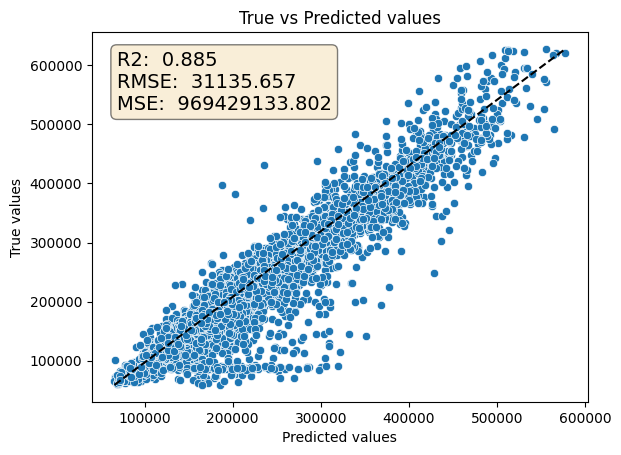

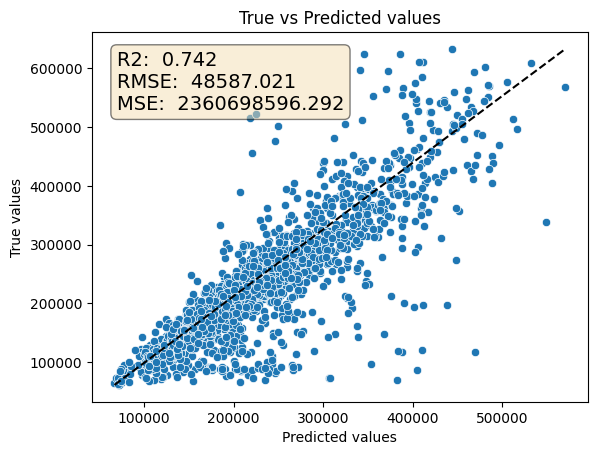

In [11]:
lgbm_model = LGBMRegressor()


if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "LightGBM"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    param_grid = {
            "n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "max_depth": optuna.distributions.IntDistribution(2, 15),
            "learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10),
            "num_leaves": optuna.distributions.IntDistribution(7, 255),
            "min_data_in_leaf": optuna.distributions.IntDistribution(20, 100),
            "subsample": optuna.distributions.FloatDistribution(0.8, 1),
            "feature_fraction": optuna.distributions.FloatDistribution(0.3, 1)
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                lgbm_model,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring='neg_root_mean_squared_error',
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = optuna_search.best_params_

    model_info = {
                "model_name": "LightGBM",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

lgbm_model = LGBMRegressor(**best_params_)
lgbm_model.fit(X_train, y_train)
y_lgbm_pred_train = lgbm_model.predict(X_train)
y_lgbm_pred_test = lgbm_model.predict(X_test)
evaluate_preds(y_train, y_lgbm_pred_train)
r2_val, rmse_val = evaluate_preds(y_test, y_lgbm_pred_test)
save_res('lightGBM', r2_val, rmse_val, res_table)


## Сравнение результатов моделей

In [12]:
res_table.sort_values(by='rmse')

,rmse,r2
CatBoost,47733.622,0.751
Градиентный бустинг,48291.32,0.745
lightGBM,48587.021,0.742
XGBoost,49013.542,0.737
Случайный лес,50039.309,0.726
Линейная регрессия,56907.684,0.646
Решающее дерево,57505.196,0.638
baseline,69593.062,0.47


По результатам тестирования выбираем `CatBoost` в качестве основной модели. Сохраним результаты предсказаний, проведем анализ сильных отклонений между предсказанным и действительным значениями и попытаемся сформулировать дополнительные правила обработки данных

In [13]:
X_merged = pd.concat([X_train, X_test], ignore_index=True).copy()
X_merged["y_true"] = pd.concat([pd.Series(y_train), pd.Series(y_test)], ignore_index=True).values
X_merged["y_pred_cb"] = pd.concat([pd.Series(y_cb_pred_train), pd.Series(y_cb_pred_test)], ignore_index=True).values

In [14]:
X_merged = reduce_mem_usage(X_merged)


Memory usage of dataframe is 1.95 MB
Memory usage after optimization is: 0.70 MB
Decreased by 64.2%


In [15]:
project_root = Path.cwd().parent

output_path = project_root / 'data' / 'interim' / 'X_train_preprocessed.csv'
output_path2 = project_root / 'data' / 'processed' / 'X_train_processed.csv'
output_path3 = project_root / 'models' / 'catboost_model.cbm'
output_path4 = project_root / 'models' / 'preprocessor.joblib'

X_merged.to_csv(output_path, index=False)
X_merged.to_csv(output_path2, index=False)

## Обучение финальной модели на всем train.csv

In [16]:
X = preprocessor.fit_transform(X, y)
cb_model.fit(X, y)
cb_model.save_model(output_path3)
joblib.dump(preprocessor, output_path4)

['d:\\regression_house_price\\models\\preprocessor.joblib']